<a href="https://colab.research.google.com/github/Amadi200/montra_hospitality/blob/main/06_baseline_sentiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Install (if needed)

In [1]:
!pip install -q scikit-learn pandas pyarrow matplotlib seaborn joblib

Imports

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)
from sklearn.pipeline import Pipeline

pd.set_option("display.max_colwidth", 120)

Mount Drive & Load Data

In [3]:
from google.colab import drive
drive.mount('/content/drive')

# Use the file that already has sentiment labels
# (You can also use the topic sentiment file)
DATA_PATH = "/content/drive/MyDrive/Montra_Hospitality/outputs/topic_sentiment/reviews_with_topic_sentiment.parquet"

df = pd.read_parquet(DATA_PATH)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Mounted at /content/drive
Shape: (34536, 31)
Columns: ['review_id', 'booking_id', 'guest_id', 'hotel_id', 'review_text', 'rating_score', 'review_date', 'sentiment_label', 'bk_guest_id', 'bk_hotel_id', 'bk_room_type', 'bk_booking_channel', 'bk_check_in_date', 'bk_check_out_date', 'bk_total_amount', 'bk_stay_duration', 'gt_customer_type', 'gt_loyalty_status', 'gt_country', 'gt_previous_stays', 'ht_hotel_name', 'ht_location', 'ht_star_rating', 'ht_total_rooms', 'review_text_ml', 'text_length', 'word_count', 'topic', 'topic_probability', 'sentiment', 'sentiment_score']


Prepare Data for Classification

In [7]:
# Use the sentiment column (adjust name if different)
# Possible names: sentiment, sentiment_label, label

if "sentiment" in df.columns:
    label_col = "sentiment"
elif "sentiment_label" in df.columns:
    label_col = "sentiment_label"
else:
    raise ValueError("No sentiment label column found. Available columns: " + str(df.columns.tolist()))

print(f"\nUsing label column: '{label_col}'")
print("\nClass distribution:")
print(df[label_col].value_counts())

# Keep only needed columns and drop missing
df_model = df[["review_text", label_col]].dropna().copy()
df_model = df_model[df_model["review_text"].str.strip() != ""]

print(f"\nFinal modelling shape: {df_model.shape}")


Using label column: 'sentiment'

Class distribution:
sentiment
Positive    21491
Negative    10120
Neutral      2925
Name: count, dtype: int64

Final modelling shape: (34536, 2)


Train / Test Split

In [8]:
X = df_model["review_text"]
y = df_model[label_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Train size: {len(X_train):,}")
print(f"Test size : {len(X_test):,}")

Train size: 27,628
Test size : 6,908


Create Pipeline (TF-IDF + Logistic Regression)

In [9]:
logreg_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=15000,          # limit vocabulary size
        ngram_range=(1, 2),          # unigrams + bigrams
        stop_words="english",
        min_df=3,
        max_df=0.9,
        sublinear_tf=True
    )),
    ("clf", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",     # helpful if classes are imbalanced
        random_state=42,
        n_jobs=-1
    ))
])

Train the model

In [10]:
print("\nTraining Logistic Regression...")
logreg_pipeline.fit(X_train, y_train)
print("Training completed!")


Training Logistic Regression...
Training completed!


Predictions & Evaluation

In [11]:
y_pred = logreg_pipeline.predict(X_test)

print("\n" + "="*60)
print("LOGISTIC REGRESSION - CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_test, y_pred, digits=4))

# Key metrics
accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")
f1_weighted = f1_score(y_test, y_pred, average="weighted")

print(f"Accuracy       : {accuracy:.4f}")
print(f"Macro F1       : {f1_macro:.4f}")
print(f"Weighted F1    : {f1_weighted:.4f}")


LOGISTIC REGRESSION - CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative     0.9784    0.9160    0.9462      2024
     Neutral     0.5062    0.9060    0.6495       585
    Positive     0.9897    0.9130    0.9498      4299

    accuracy                         0.9133      6908
   macro avg     0.8247    0.9117    0.8485      6908
weighted avg     0.9454    0.9133    0.9233      6908

Accuracy       : 0.9133
Macro F1       : 0.8485
Weighted F1    : 0.9233


Confusion Matrix

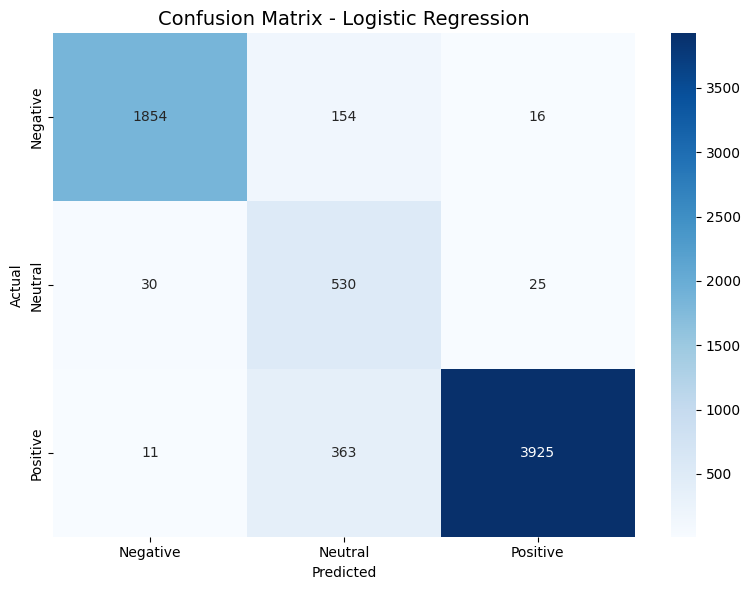

In [12]:
cm = confusion_matrix(y_test, y_pred, labels=logreg_pipeline.classes_)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=logreg_pipeline.classes_,
    yticklabels=logreg_pipeline.classes_
)
plt.title("Confusion Matrix - Logistic Regression", fontsize=14)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

Save the model & results

In [13]:
output_dir = Path("/content/drive/MyDrive/Montra_Hospitality/outputs/baseline_models")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the trained pipeline
joblib.dump(logreg_pipeline, output_dir / "logistic_regression_tfidf.joblib")

# Save predictions for later analysis
results_df = pd.DataFrame({
    "review_text": X_test,
    "actual": y_test,
    "predicted": y_pred
})
results_df.to_parquet(output_dir / "logreg_predictions.parquet", index=False)

# Save metrics
metrics = {
    "model": "Logistic Regression + TF-IDF",
    "accuracy": accuracy,
    "macro_f1": f1_macro,
    "weighted_f1": f1_weighted
}
pd.DataFrame([metrics]).to_csv(output_dir / "logreg_metrics.csv", index=False)

print(f"\nModel and results saved to:\n{output_dir}")


Model and results saved to:
/content/drive/MyDrive/Montra_Hospitality/outputs/baseline_models
